# 08-02 - A Graph Convolutional Network on Streets

You turn Princeton's street segments into a graph, train a graph convolutional network on their speed limits, and check what the graph adds.

First the segments, the street graph and a graph that knows only distance. Then the model without a graph, one layer by hand on Nassau Street, the GCN on both graphs, where each is right and how many weights each has. Then the same layer from a library, and you change the number of layers.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import graph_tools as gt

plt.rcParams["figure.dpi"] = 72

scene = gt.load_json("data/scene.json")
reference = gt.load_json("data/ground_truth.json")["p08"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
torch_ok, pyg_ok = gt.torch_ok, gt.pyg_available()
streets, metr = lecture["streets"], lecture["metr"]
print(f"seed {scene['seed']}; {streets['n']:,} street segments, {streets['tagged']} with a speed limit")
print(f"{metr['sensors']} traffic sensors; PyTorch {'ready' if torch_ok else 'missing'}, "
      f"PyTorch Geometric {'ready' if pyg_ok else 'missing'}")

seed 20261116; 1,219 street segments, 454 with a speed limit
207 traffic sensors; PyTorch ready, PyTorch Geometric ready


## Speed limits on the map

The cell loads the 1,219 street segments of the lecture, counts the speed limit classes OpenStreetMap carries and maps them, with the untagged segments pale.

25 mph or less        280 segments   lecture 280
30 mph                 53 segments   lecture 53
35 mph                 76 segments   lecture 76
40 mph or more         45 segments   lecture 45
no limit on the map   765 segments   lecture 765
1,219 segments drawn, 454 with a limit


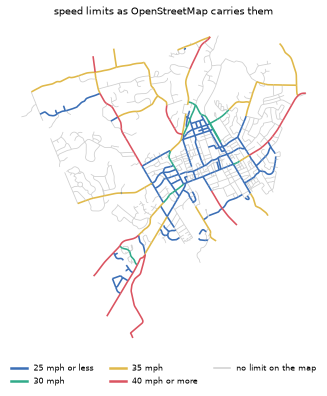

In [2]:
s = gt.load_arrays("data/streets.npz")
segments = gt.load_segments()
y, n = gt.street_classes(s), lecture["numbers"]
counts = np.bincount(s["y"][s["tagged"]], minlength=4)
for name, c in zip(gt.SPEED_NAMES, counts):
    print(f"{name:20s} {c:4d} segments   lecture {lecture['streets']['classes'][name]}")
print(f"{'no limit on the map':20s} {(~s['tagged']).sum():4d} segments   "
      f"lecture {lecture['streets']['untagged']}")
print(f"{len(segments):,} segments drawn, {s['tagged'].sum()} with a limit")
gt.show_streets(segments, classes=s["y"], title="speed limits as OpenStreetMap carries them")
plt.show()

Only 454 of the 1,219 segments carry a limit, and 280 of those are 25 mph or less. The coloured lines are the roads that run out of town in yellow and red and the downtown grid in blue, while the pale web of suburban streets has almost no tag. That matters later. A model trained on the tagged segments learns mostly from the larger roads, and the 30 mph class has only 53 examples in the whole town.

## Segments become nodes

Each segment runs between two intersections, given as `u` and `v`. The cell joins two segments wherever they share an intersection and compares the result with the shipped street graph.

In [3]:
ends = list(zip(s["u"], s["v"]))
A = gt.line_graph(ends)
print(f"{len(ends):,} segments, the first runs from intersection {ends[0][0]} to {ends[0][1]}")
print(f"repeated pairs {len(ends) - len(set(map(frozenset, ends)))}, segments that start where they end "
      f"{(s['u'] == s['v']).sum()}")
print("built graph equals the shipped street graph:", np.array_equal(A, s["A_street"]))
print(f"{int(np.triu(A, 1).sum()):,} edges, mean degree {A.sum(1).mean():.1f}   "
      f"lecture {lecture['streets']['m_street']:,} edges, mean degree {n['st degree']}")
print("segments by degree:", {int(d): int(c) for d, c in zip(*np.unique(A.sum(1), return_counts=True))})

1,219 segments, the first runs from intersection 103943085 to 103943088
repeated pairs 0, segments that start where they end 0
built graph equals the shipped street graph: True
2,377 edges, mean degree 3.9   lecture 2,377 edges, mean degree 3.9
segments by degree: {1: 4, 2: 190, 3: 101, 4: 613, 5: 251, 6: 60}


This is the line graph of Lecture 07's drive network, where intersections were the nodes and segments the edges. The check needs one segment per pair of intersections and no loop, which the two zeros confirm, and then the built matrix is the shipped one. A typical segment meets about two others at each end, so 613 segments have degree four and the mean is 3.9. A segment that ends in a cul de sac meets others at one end only, so its degree is low.

## Two graphs over one town

The proximity graph joins the 2,377 closest pairs of midpoints, as many edges as the street graph. The cell draws both over the town centre.

proximity graph 2,377 edges, shared with the street graph 1,303, 55 percent   lecture 1,303, 55 percent


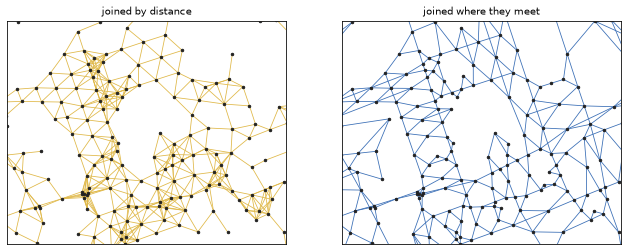

In [4]:
A_near = s["A_near"].astype(float)
shared = int(np.triu(A * A_near, 1).sum())
print(f"proximity graph {int(np.triu(A_near, 1).sum()):,} edges, shared with the street graph {shared:,}, "
      f"{100 * shared / lecture['streets']['m_street']:.0f} percent   "
      f"lecture {n['st shared']}, {n['st shared pct']} percent")
window = (528200, 529600, 4466590, 4467710)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
gt.show_edges(s["mid"], A_near, ax=axes[0], colour=gt.GRAPH_COLOURS["proximity"], window=window,
              title="joined by distance")
gt.show_edges(s["mid"], A, ax=axes[1], colour=gt.GRAPH_COLOURS["streets"], window=window,
              title="joined where they meet")
plt.show()

Every dot is the midpoint of a segment. On the right the edges follow the streets, a chain along each road with a small knot at every crossing, and long segments reach out of the crop. On the left the edges join whatever lies close, so short segments downtown form dense clusters while long ones get few edges. More than half of the edges are the same in both graphs, so the comparison hinges on the other 45 percent.

## Near in metres, far along streets

The lecture marks one pair joined by distance. The cell counts how many edges separate the two segments on the street graph and colours the crop by that count.

segment 604: ['South Stanworth Drive', 'North Stanworth Drive', 'East Stanworth Drive']
segment 1059: John Street
115 m apart, joined by distance: True, 7 edges apart on the streets   lecture 115 m, 7 edges


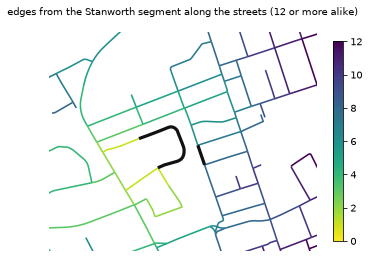

In [5]:
a, b = 604, 1059  # the pair the lecture marks on its figure of the three graphs
steps_a = gt.hops(A, a)
metres = np.hypot(*(s["mid"][a] - s["mid"][b]))
print(f"segment {a}: {s['name'][a]}\nsegment {b}: {s['name'][b]}")
print(f"{metres:.0f} m apart, joined by distance: {bool(A_near[a, b])}, "
      f"{steps_a[b]:.0f} edges apart on the streets   lecture {n['st pair m']} m, {n['st pair hops']} edges")
ax = gt.show_streets(segments, values=np.minimum(steps_a, 12), mark=[a, b], cmap="viridis_r",
                     title="edges from the Stanworth segment along the streets (12 or more alike)")
ax.set_xlim(527900, 529000)
ax.set_ylim(4466750, 4467650)
plt.show()

The two dark segments are 115 m apart, close enough to be joined by distance. Along the streets the colour climbs from yellow beside the curved Stanworth segment to teal beside John Street, because the two share a block but no junction and the shortest way round passes six other segments. The proximity graph mixes their limits in one step, while the street graph keeps them seven steps apart.

## Neighbours share a limit

Homophily is the share of edges whose two ends carry the same class, counted over edges between two tagged segments. The cell compares it with chance.

In [6]:
tagged = s["tagged"]
share = counts / counts.sum()
print(f"street graph {gt.homophily(A, s['y'], tagged):.2f}   "
      f"lecture {lecture['streets']['homophily_street']:.2f}")
print(f"proximity graph {gt.homophily(A_near, s['y'], tagged):.2f}   "
      f"lecture {lecture['streets']['homophily_near']:.2f}")
print(f"two tagged segments drawn at random share a class with chance {(share * share).sum():.2f}")
only_street, only_near = A * (1 - A_near), A_near * (1 - A)
print(f"edges in both graphs {gt.homophily(A * A_near, s['y'], tagged):.2f}, "
      f"only on the streets {gt.homophily(only_street, s['y'], tagged):.2f}, "
      f"only by distance {gt.homophily(only_near, s['y'], tagged):.2f}")

street graph 0.81   lecture 0.81
proximity graph 0.82   lecture 0.82
two tagged segments drawn at random share a class with chance 0.43
edges in both graphs 0.87, only on the streets 0.77, only by distance 0.75


Both graphs join segments of one class about four times in five, against 0.43 for two segments drawn at random. So averaging over neighbours should help on either graph. The proximity graph even scores a touch higher, which warns that homophily alone does not predict which graph helps more. What matters is where the edges lie relative to the labelled segments, and the training runs below decide.

## Features, classes and the split

The cell builds the 71 features of the lecture's run, draws its split of the tagged segments, and checks the split against the shipped run.

In [7]:
F67, F = gt.street_features(s, "geometry and embedding"), gt.street_features(s, "with the road class")
print(f"features {F67.shape[1]} (log length, bearing as two numbers, 64 of the embedding), "
      f"with the road class {F.shape[1]}")
lab, val, test = gt.split_streets(s, "random", np.random.default_rng(scene["seed"] + 1))
main, G = gt.load_arrays("data/lecture_main.npz"), gt.street_graphs(s)
for part, idx in (("labelled", lab), ("validation", val), ("test", test)):
    print(f"{part:10s} {len(idx):3d} segments, by class {np.bincount(y[idx], minlength=4)}")
print(f"lecture: labelled {lecture['main']['labelled_per_class']}, test {lecture['main']['test_per_class']}; "
      f"same split {np.array_equal(lab, main['labelled']) and np.array_equal(test, main['test'])}")
print(f"majority rule {100 * gt.majority_accuracy(y, lab, test):.1f} percent   lecture {n['st majority']}")

features 67 (log length, bearing as two numbers, 64 of the embedding), with the road class 71
labelled   150 segments, by class [102  11  25  12]
validation 100 segments, by class [63 10 15 12]
test       204 segments, by class [115  32  36  21]
lecture: labelled [102, 11, 25, 12], test [115, 32, 36, 21]; same split True
majority rule 56.4 percent   lecture 56.4


Every feature is standardised so no unit outweighs another. The 150 labelled segments train the model, the 100 validation segments pick the epoch to keep, and the 204 test segments are scored once at the end. Only 11 labelled segments are 30 mph. Always saying 25 mph or less already scores 56.4 percent on the test, the floor every model has to clear. The 765 untagged segments stay in the graph without a label.

## The model without a graph

The cell trains the lecture's baseline, two layers that look at one segment at a time, for 200 epochs on the labelled segments.

In [8]:
if torch_ok:
    runs, models = {}, {}
    runs["none"], models["none"] = gt.train(F, G["none"], y, lab, val, seed=scene["seed"])
    acc = 100 * gt.accuracy(runs["none"]["pred"], y, test)
    print(f"no graph {acc:.1f} percent right on {len(test)} test segments, "
          f"best epoch {runs['none']['best_epoch']}   lecture {n['st mlp']}, epoch {n['st mlp epoch']}")
    print("the same prediction for every segment as the lecture's run:", np.array_equal(runs["none"]["pred"],
                                                                                       main["mlp_pred"]))
else:
    print(gt.NO_TORCH)

no graph 66.7 percent right on 204 test segments, best epoch 83   lecture 66.7, epoch 83
the same prediction for every segment as the lecture's run: True


Look at the gap between this score and the majority rule above. Length, bearing, road class and the satellite numbers lift the model about ten points over always saying 25, and the lecture's run reached 66.7 percent. The last line says whether your laptop reproduced that run segment for segment. Torch runs on one thread here, so it usually does, but a different processor may move a few segments.

## One layer by hand

A GCN layer averages a segment's features with those of the segments it meets. The cell prints the weights of that average for one segment of Nassau Street.

segment  525 Nassau Street    degree with its loop 5, weight 0.200 = 1 / sqrt(5 x 5)
segment  526 Chestnut Street  degree with its loop 6, weight 0.183 = 1 / sqrt(5 x 6)
segment  527 Nassau Street    degree with its loop 5, weight 0.200 = 1 / sqrt(5 x 5)
segment  528 Olden Street     degree with its loop 5, weight 0.200 = 1 / sqrt(5 x 5)
segment  529 Nassau Street    degree with its loop 5, weight 0.200 = 1 / sqrt(5 x 5)
the weights add up to 0.983; the weighted average of the first feature, the standardised log length, is -0.51 against the segment's own -1.76


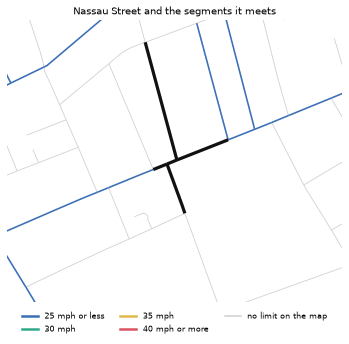

In [9]:
i, degree = anchors["nassau"], A.sum(1) + 1
row = G["streets"][i]
for j in np.nonzero(row)[0]:
    print(f"segment {j:4d} {str(s['name'][j]):16s} degree with its loop {degree[j]:.0f}, weight {row[j]:.3f}"
          f" = 1 / sqrt({degree[i]:.0f} x {degree[j]:.0f})")
print(f"the weights add up to {row.sum():.3f}; the weighted average of the first feature, the standardised "
      f"log length, is {np.dot(row, F[:, 0]):.2f} against the segment's own {F[i, 0]:.2f}")
ax = gt.show_streets(segments, classes=s["y"], mark=np.nonzero(row)[0],
                     title="Nassau Street and the segments it meets")
ax.set_xlim(529150, 529900)
ax.set_ylim(4466560, 4467190)
plt.show()

The segment meets four others, the dark lines on the map with the segment itself, so five rows of the feature table enter the average. Each weight is one over the square root of the two degrees, so a neighbour that meets many segments counts a little less, as Chestnut Street does here. The weights do not add up to exactly one, which is the symmetric rule of the lecture and not a plain mean. The layer then multiplies this average by the same weight matrix for every segment.

## The GCN on two graphs

The cell trains the same two layers on the proximity graph and on the street graph, same split, same start, and draws the validation loss of all three runs.

proximity 69.1 percent right, best epoch  44   lecture 69.1, epoch 44; same as lecture True


streets   77.0 percent right, best epoch  50   lecture 77.0, epoch 50; same as lecture True


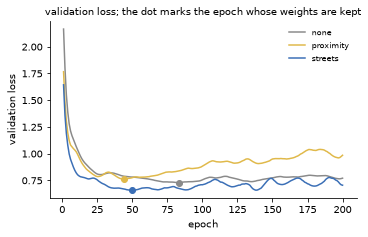

In [10]:
if torch_ok:
    for key, short in (("proximity", "near"), ("streets", "gcn")):
        runs[key], models[key] = gt.train(F, G[key], y, lab, val, seed=scene["seed"])
        acc = 100 * gt.accuracy(runs[key]["pred"], y, test)
        print(f"{key:9s} {acc:.1f} percent right, best epoch {runs[key]['best_epoch']:3d}   "
              f"lecture {n['st ' + short]}, epoch {lecture['main'][short]['best_epoch']}; same as lecture "
              f"{np.array_equal(runs[key]['pred'], main[short + '_pred'])}")
    gt.show_curves(runs, title="validation loss; the dot marks the epoch whose weights are kept")
    plt.show()
else:
    print(gt.NO_TORCH)

The lecture's run scored 69.1 percent on the proximity graph and 77.0 on the street graph, with the same 71 inputs. Compare your lines with those numbers. In the curves look for which model falls fastest and lowest, and which one turns up soonest after its dot. Where a curve turns up the model has begun to memorise its 150 labels, and early stopping keeps the weights of the dot.

## Right and wrong on the test

The cell maps the test segments for both models, right ones in their class colour and wrong ones in black, and counts the 30 mph class.

30 mph named right: no graph 1 of 32, street graph 17   lecture 1 and 17
fixed by the graph 34, broken 13   lecture 34, 13


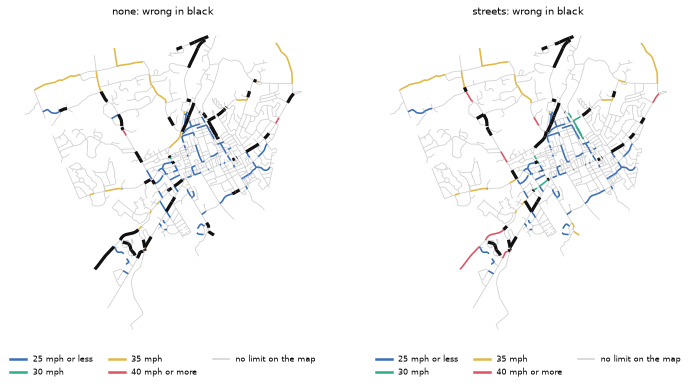

In [11]:
pred = ({k: runs[k]["pred"] for k in ("none", "streets")} if torch_ok
        else {"none": main["mlp_pred"], "streets": main["gcn_pred"]})
M = {k: gt.confusion(p, y, 4, test) for k, p in pred.items()}
right = {k: p[test] == y[test] for k, p in pred.items()}
print(f"30 mph named right: no graph {M['none'][1, 1]} of {M['none'][1].sum()}, "
      f"street graph {M['streets'][1, 1]}   lecture {n['st mlp c30 right']} and {n['st gcn c30 right']}\n"
      f"fixed by the graph {(~right['none'] & right['streets']).sum()}, "
      f"broken {(right['none'] & ~right['streets']).sum()}   lecture {n['st fixed']}, {n['st broken']}")
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, k in zip(axes, pred):
    shown = np.where(np.isin(np.arange(len(y)), test[right[k]]), y, -1)
    gt.show_streets(segments, classes=shown, mark=test[~right[k]], ax=ax, title=f"{k}: wrong in black")

Without a graph the model calls nearly every 30 mph segment 25, because nothing in a segment's own numbers says 30. The lecture's street GCN names 17 of the 32 right, against 1 without the graph, since a limit continues along a road and a segment hears its labelled neighbours. On the right map green segments appear downtown where the left map is black. The graph also breaks some segments, mostly where a limit changes at a junction.

## The hidden space in two numbers

After the first layer every segment has 32 hidden numbers. The cell squeezes them into the two directions of largest spread for both models, tagged segments coloured by class.

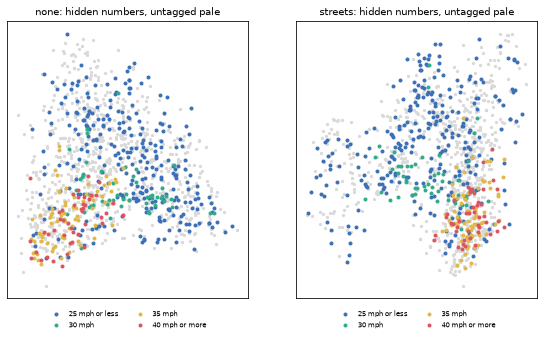

In [12]:
hidden = ({k: runs[k]["hidden"] for k in ("none", "streets")} if torch_ok
          else {"none": main["mlp_hidden"], "streets": main["gcn_hidden"]})
fig, axes = plt.subplots(1, 2, figsize=(9.5, 5))
for ax, (k, H) in zip(axes, hidden.items()):
    gt.show_scatter(gt.two_numbers(H), y, ax=ax, dim=~tagged, title=f"{k}: hidden numbers, untagged pale")
plt.show()

Without a graph the 30 mph points, green, sit among the blue 25 mph points, so the straight cuts of the second layer cannot pull them out. With the street graph segments that meet get close hidden numbers, because they average over nearly the same neighbourhood, and the green points gather in a band between blue and the yellow and red. Yellow and red overlap in both pictures. The pale untagged segments fall among the tagged ones.

## The same number of weights

The cell lists the learned numbers of the model without a graph and of the street GCN, layer by layer.

In [13]:
if torch_ok:
    for key in ("none", "streets"):
        shapes = [tuple(p.shape) for p in models[key].parameters()]
        print(f"{key:8s} {gt.count_parameters(models[key]):,} learned numbers, shapes {shapes}")
    print(f"71 x 32 + 32 + 32 x 4 + 4 = {71 * 32 + 32 + 32 * 4 + 4:,}   lecture {n['st params']}")
else:
    print(gt.NO_TORCH)

none     2,436 learned numbers, shapes [(32, 71), (32,), (4, 32), (4,)]
streets  2,436 learned numbers, shapes [(32, 71), (32,), (4, 32), (4,)]
71 x 32 + 32 + 32 x 4 + 4 = 2,436   lecture 2,436


Both models hold 2,436 numbers. The first layer has a weight matrix of 32 rows and 71 columns, 2,272 numbers, and 32 biases. The second has 4 rows of 32, another 128, and 4 biases. The graph adds no weight at all, it only decides whose features get averaged before each layer. So the ten points between 66.7 and 77.0 in the lecture's run come from the graph and not from a larger model.

## The same layer from a library

PyTorch Geometric builds the same network from its `GCNConv` layer. The cell copies the trained weights into it and compares the class scores of every segment.

In [14]:
if torch_ok and pyg_ok:
    edge_index = gt.to_edge_index(s["A_street"])
    print(f"edge list of shape {edge_index.shape}, the first columns\n{edge_index[:, :6]}")
    library = gt.pyg_gcn(F.shape[1], 32, 4)
    gt.copy_weights(models["streets"], library)
    gap = np.abs(gt.scores(models["streets"], F, G["streets"]) - gt.scores(library, F, edge_index)).max()
    print(f"{gt.count_parameters(library):,} learned numbers; "
          f"largest difference of the scores, biases set to zero, {gap:.1e}")
else:
    print(gt.NO_TORCH if not torch_ok else gt.NO_PYG)

edge list of shape (2, 4754), the first columns
[[0 0 1 1 1 1]
 [1 2 0 2 3 4]]
2,436 learned numbers; largest difference of the scores, biases set to zero, 1.9e-06


The library keeps the graph as a list of edges, two rows of segment numbers with one column for each direction, so 4,754 columns for 2,377 edges. It adds the self loops and the symmetric weights itself. Our layer adds its bias before the average, the library after it, so the copy sets both biases to zero first. The two models then differ only by rounding, a gap of about a millionth.

## The library's model trained

The cell trains the library's network from the same start, on the same split and for the same 200 epochs, and puts its score beside the model written by hand.

In [15]:
if torch_ok and pyg_ok:
    library = gt.pyg_gcn(F.shape[1], 32, 4)
    run_lib = gt.fit(library, F, edge_index, y, lab, val, seed=scene["seed"])
    print(f"library {100 * gt.accuracy(run_lib['pred'], y, test):.1f} percent right, "
          f"best epoch {run_lib['best_epoch']}")
    print(f"by hand {100 * gt.accuracy(runs['streets']['pred'], y, test):.1f} percent right, "
          f"best epoch {runs['streets']['best_epoch']}")
    print(f"segments where the two disagree {(run_lib['pred'] != runs['streets']['pred']).sum()}")
else:
    print(gt.NO_TORCH if not torch_ok else gt.NO_PYG)

library 77.0 percent right, best epoch 50
by hand 77.0 percent right, best epoch 50
segments where the two disagree 4


The two networks start from the same weights, because the biases start at zero and the weight matrices are drawn in the same order. Training then moves the biases, and since they sit on different sides of the average the runs can drift apart. Read the two scores and the count of segments where they disagree. Small differences are expected and say nothing about either model, and the library is what you would use on a graph of a million segments.

## Your turn

With two layers a segment hears the segments two steps away. The cell counts them around Nassau Street, draws the circle of the same radius, and trains a GCN that deep. Run the cell as it is, then change the marked value and run it again.

What happens to the score at eight layers, and how does the reach compare with the circle? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [16]:
LAYERS = 2  # change me: 8
steps = gt.hops(A, anchors["nassau"])
dist = np.hypot(*(s["mid"] - s["mid"][anchors["nassau"]]).T)
radius = dist[steps <= LAYERS].max()
print(f"{LAYERS} steps from Nassau Street reach {(steps <= LAYERS).sum()} segments, "
      f"the farthest {radius:.0f} m away; a circle of that radius holds {(dist <= radius).sum()}")
if torch_ok:
    deep, _ = gt.train(F, G["streets"], y, lab, val, seed=scene["seed"], layers=LAYERS)
    print(f"street GCN with {LAYERS} layers: {100 * gt.accuracy(deep['pred'], y, test):.1f} percent right, "
          f"best epoch {deep['best_epoch']}")
else:
    print(gt.NO_TORCH)

2 steps from Nassau Street reach 14 segments, the farthest 325 m away; a circle of that radius holds 34


street GCN with 2 layers: 77.0 percent right, best epoch 50


## Check your understanding

1. The proximity graph has as many edges as the street graph and a touch higher homophily, yet scored lower. What do its own edges join that the streets do not?
2. The model without a graph named 1 of 32 segments at 30 mph right. What would a feature have to describe to help it?
3. Both models hold 2,436 learned numbers. Why does that make the comparison fair?
4. Every score here comes from one split and one start. What would you check before telling the town that the graph helps?

## Where we are

You have turned 1,219 segments into the line graph of the drive network, set a graph that knows only distance beside it, worked one layer by hand on Nassau Street, trained the model without a graph and the GCN on both graphs, read where each one is right and how its hidden numbers sit, and rebuilt the layer from a library. All of it rests on one draw of 150 labels. In 08-03 the one run becomes twenty draws, four feature sets and a split by blocks, and we ask whether the graph still helps.

## Further resources

Nothing in this course requires anything below.

- Semi-Supervised Classification with Graph Convolutional Networks, Thomas N. Kipf and Max Welling, ICLR 2017, https://arxiv.org/abs/1609.02907
- Introduction by Example, the PyTorch Geometric documentation, https://pytorch-geometric.readthedocs.io/en/latest/get_started/introduction.html
- Graph Representation Learning, William L. Hamilton, Morgan and Claypool 2020, chapter 5, The Graph Neural Network Model, https://www.cs.mcgill.ca/~wlh/grl_book/

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The street segments, their names and their speed limits derive from OpenStreetMap, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright The 64 embedding numbers of every segment come from the AlphaEarth Foundations Satellite Embedding dataset, produced by Google and Google DeepMind, CC BY 4.0. PyTorch Geometric is the library of Fey and Lenssen (2019), MIT licence.